# Ekstraopgaver til notebook 2: løsningsforslag

Dette er løsningsforslaget til `02_pandas_ishuset_ekstra.ipynb`. Opgaveteksterne er de samme som i opgavenotebooken. I kodecellerne er `___` erstattet med en løsning, og under hver tekstopgave står et løsningsforslag. Der findes ofte flere rigtige løsninger end den, der er vist.

To celler fejler med vilje (i opgave A3 og C2). Kør derfor cellerne én ad gangen i stedet for at bruge Run all.

---
## Blok A: Lær data at kende (til øvelse 4)

In [1]:
# Opsætning til blok A: kør denne celle først
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/da/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Omsætning"] = df["Antal"] * df["EnhedsPris"]
print("Data er klar:", df.shape)

Data er klar: (300, 7)


### Opgave A1: Tal og tekst

`df.dtypes` viser, hvilken type hver kolonne har. Talkolonner vises som `int64` eller `float64`. Tekstkolonner vises som `object` eller `str`, afhængigt af hvilken version af pandas Colab kører. Datoer vises som `datetime64`.

Kør cellen. Kør derefter de to linjer under den: `.unique()` viser de forskellige værdier i en kolonne, og `.nunique()` tæller dem.

In [2]:
df.dtypes

SalgsId                int64
Dato          datetime64[ns]
Butik                 object
Vare                  object
Antal                  int64
EnhedsPris             int64
Omsætning              int64
dtype: object

In [3]:
print(df["Butik"].unique())
print(df["Vare"].nunique())

['Aalborg C' 'Skagen' 'Blokhus' 'Løkken']
6


**Svar med tekst:** Hvilke kolonner er tal, og hvilke er tekst? Hvorfor giver det mening at beregne et gennemsnit af `Antal`, men ikke af `Butik`?

**Løsningsforslag:** `SalgsId`, `Antal`, `EnhedsPris` og `Omsætning` er tal, `Butik` og `Vare` er tekst, og `Dato` er en dato. Et gennemsnit kræver tal, man kan lægge sammen og dele. `Butik` er en kategori, så der giver det mening at tælle, fx med `value_counts()`, men ikke at beregne et gennemsnit. Bemærk også, at `SalgsId` er et tal, men et løbenummer, så et gennemsnit af den kolonne er teknisk muligt og fagligt meningsløst.

### Opgave A2: Hvilken periode dækker data?

Find antallet af forskellige datoer i data, den første dato og den sidste dato. Brug `.nunique()`, `.min()` og `.max()` på kolonnen `Dato`.

I udskriften bruges formatkoden `%d.%m.%Y`, som viser en dato på dansk form, fx 01.06.2026.

In [4]:
antal_dage = df["Dato"].nunique()
foerste = df["Dato"].min()
sidste = df["Dato"].max()
print(f"{antal_dage} dage fra {foerste:%d.%m.%Y} til {sidste:%d.%m.%Y}")

61 dage fra 01.06.2026 til 31.07.2026


In [5]:
#@title Forventet output (klik for at vise)
print("61 dage fra 01.06.2026 til 31.07.2026")

61 dage fra 01.06.2026 til 31.07.2026


### Opgave A3: Filtrér på to betingelser

Når du vil have rækker, der opfylder to betingelser på én gang, sætter du `&` (og) imellem dem. Hver betingelse skal stå i sin egen parentes. Cellen herunder mangler parenteserne og fejler med vilje. Kør den og se fejlbeskeden.

In [6]:
# ⚠️ Denne celle fejler med vilje
df[df["Butik"] == "Skagen" & df["Antal"] >= 3]

TypeError: Cannot perform 'rand_' with a dtyped [int64] array and scalar of type [bool]

Uden parenteser forsøger Python at regne `"Skagen" & df["Antal"]` ud først, og det giver ingen mening. Skriv nu filteret rigtigt: varelinjer fra Skagen med mindst 3 styk. Gem resultatet i `skagen_store` og udskriv antallet af rækker med `len()`.

In [7]:
skagen_store = df[(df["Butik"] == "Skagen") & (df["Antal"] >= 3)]
print(len(skagen_store))

23


In [8]:
#@title Tjek dit svar (kør cellen)
print("Rigtigt" if len(skagen_store) == 23 else "Ikke endnu: tjek begge betingelser, og husk at mindst 3 skrives >= 3")

Rigtigt


### Opgave A4: Uden mønster

Opgaven står kun som en kommentar. Mønstrene findes i blokkens tidligere opgaver og i notebook 2.

In [9]:
# Hvor mange varelinjer med Softice er der i Blokhus, og hvor mange softice er der solgt i alt på dem?
# Udskriv svaret i sætningen: "... varelinjer med i alt ... softice" med dine egne tal.
blokhus_softice = df[(df["Butik"] == "Blokhus") & (df["Vare"] == "Softice")]
print(f"{len(blokhus_softice)} varelinjer med i alt {blokhus_softice['Antal'].sum()} softice")

19 varelinjer med i alt 40 softice


In [10]:
#@title Forventet output (klik for at vise)
print("19 varelinjer med i alt 40 softice")

19 varelinjer med i alt 40 softice


---
## Blok B: Totaler pr. gruppe (til øvelse 5)

In [11]:
# Opsætning til blok B: kør denne celle først
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/da/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Omsætning"] = df["Antal"] * df["EnhedsPris"]
print("Data er klar:", df.shape)

Data er klar: (300, 7)


### Opgave B1: groupby

I øvelse 5 sammenlignede du butikkerne ved at filtrere én butik ad gangen. Med `groupby` kan du gøre det for alle butikker på én gang: `df.groupby("Butik")["Omsætning"].sum()` deler data op efter butik og lægger omsætningen sammen i hver gruppe.

Beregn den samlede omsætning pr. butik, og sortér resultatet, så den største står øverst.

In [12]:
oms_pr_butik = df.groupby("Butik")["Omsætning"].sum()
oms_pr_butik = oms_pr_butik.sort_values(ascending=False)
print(oms_pr_butik)

Butik
Aalborg C    14505
Blokhus      10217
Løkken        6853
Skagen        5411
Name: Omsætning, dtype: int64


In [13]:
#@title Forventet output (klik for at vise)
print("Du skal se fire butikker i denne rækkefølge:")
print("Aalborg C 14505, Blokhus 10217, Løkken 6853, Skagen 5411")

Du skal se fire butikker i denne rækkefølge:
Aalborg C 14505, Blokhus 10217, Løkken 6853, Skagen 5411


### Opgave B2: Gennemsnit pr. vare som søjlediagram

Beregn det gennemsnitlige antal styk pr. varelinje for hver vare, sortér fra størst til mindst, og vis resultatet som et søjlediagram. `plt.bar(x, højde)` tegner søjler. Navnene på varerne findes i `.index`, og tallene i `.values`.

Vare
Vaffel 3 kugler    2.78
Vaffel 2 kugler    2.56
Slushice           2.55
Milkshake          2.44
Vaffel 1 kugle     2.43
Softice            2.40
Name: Antal, dtype: float64


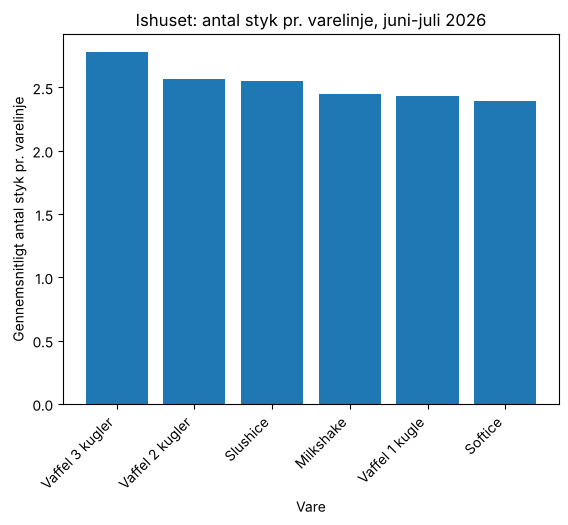

In [14]:
snit_antal = df.groupby("Vare")["Antal"].mean().sort_values(ascending=False)
print(snit_antal.round(2))

plt.bar(snit_antal.index, snit_antal.values)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Vare")
plt.ylabel("Gennemsnitligt antal styk pr. varelinje")
plt.title("Ishuset: antal styk pr. varelinje, juni-juli 2026")
plt.show()

In [15]:
#@title Forventet output (klik for at vise)
print("Du skal se seks søjler fra Vaffel 3 kugler (ca. 2,78) til Softice (ca. 2,40).")
print("Forskellene er små: på alle varer køber kunderne i gennemsnit 2 til 3 styk.")

Du skal se seks søjler fra Vaffel 3 kugler (ca. 2,78) til Softice (ca. 2,40).
Forskellene er små: på alle varer køber kunderne i gennemsnit 2 til 3 styk.


### Opgave B3: Uden mønster

`.idxmax()` giver navnet (indekset) på den største værdi, og `.max()` giver selve værdien.

In [16]:
# Find den dato, hvor Ishuset havde den største samlede omsætning, og hvor stor den var.
# Udskriv svaret i sætningen: "Højeste omsætning: dd.mm.åååå med ... kr."
oms_pr_dag = df.groupby("Dato")["Omsætning"].sum()
bedste_dag = oms_pr_dag.idxmax()
print(f"Højeste omsætning: {bedste_dag:%d.%m.%Y} med {oms_pr_dag.max()} kr.")

Højeste omsætning: 25.07.2026 med 1153 kr.


In [17]:
#@title Forventet output (klik for at vise)
print("Højeste omsætning: 25.07.2026 med 1153 kr.")

Højeste omsætning: 25.07.2026 med 1153 kr.


---
## Blok C: Fra datatabel til matrix

I Del 4 i notebook 1 regnede du prikproduktet af et antal og en pris. Her laver du først en tabel over solgte styk med én række pr. butik og én kolonne pr. vare. Tabellen er en matrix, og ganget med en prisvektor giver den omsætningen for alle butikker på én gang.

In [18]:
# Opsætning til blok C: kør denne celle først
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/da/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Omsætning"] = df["Antal"] * df["EnhedsPris"]
print("Data er klar:", df.shape)

Data er klar: (300, 7)


### Opgave C1: Pivottabel

`pd.pivot_table` laver en krydstabel: `index` bliver rækkerne, `columns` bliver kolonnerne, `values` er det tal, der samles, og `aggfunc="sum"` lægger tallene sammen. `fill_value=0` sætter 0 ind, hvor en butik ikke har solgt en vare.

Lav tabellen over solgte styk med butikker som rækker og varer som kolonner.

In [19]:
tabel = pd.pivot_table(df, index="Butik", columns="Vare", values="Antal", aggfunc="sum", fill_value=0)
tabel

Vare,Milkshake,Slushice,Softice,Vaffel 1 kugle,Vaffel 2 kugler,Vaffel 3 kugler
Butik,,,,,,
Aalborg C,30,49,44,36,105,41
Blokhus,32,17,40,9,71,35
Løkken,8,18,39,4,49,23
Skagen,18,13,28,2,34,15


In [20]:
#@title Tjek dit svar (kør cellen)
print("Rigtigt" if tabel.shape == (4, 6) and tabel.loc["Aalborg C", "Vaffel 2 kugler"] == 105 else "Ikke endnu: butikker skal være rækker, varer kolonner og Antal værdierne")

Rigtigt


### Opgave C2: Matrix gange prisvektor

Pivottabellen sorterer varerne alfabetisk, så kolonnerne står i rækkefølgen Milkshake, Slushice, Softice, Vaffel 1 kugle, Vaffel 2 kugler, Vaffel 3 kugler. Prisvektoren skal stå i præcis samme rækkefølge, ellers bliver resultatet forkert, uden at Python melder fejl.

Først et eksempel på, hvad der sker, hvis man skriver priserne i menukortets rækkefølge. Kør cellen.

In [21]:
M = tabel.to_numpy()                                # tabellen som numpy-matrix
priser_menu = np.array([38, 50, 62, 45, 55, 35])    # menukortets rækkefølge: FORKERT her
print(M @ priser_menu)

[15148 10081  7302  5555]


Den sikre måde er at hente priserne fra data og stille dem i samme rækkefølge som tabellens kolonner med `priser[tabel.columns]`. Udfyld hullet, så `oms_matrix` bliver omsætningen pr. butik.

In [22]:
priser = df.groupby("Vare")["EnhedsPris"].first()   # én pris pr. vare
priser = priser[tabel.columns]                      # samme rækkefølge som kolonnerne
print(priser)

oms_matrix = M @ priser.to_numpy()
print(oms_matrix)

Vare
Milkshake          55
Slushice           35
Softice            45
Vaffel 1 kugle     38
Vaffel 2 kugler    50
Vaffel 3 kugler    62
Name: EnhedsPris, dtype: int64
[14505 10217  6853  5411]


Sammenlign med omsætningen pr. butik beregnet med `groupby`. Både pivottabellen og `groupby` sorterer butikkerne alfabetisk, så rækkefølgen er den samme.

In [23]:
oms_groupby = df.groupby("Butik")["Omsætning"].sum().to_numpy()
print(oms_groupby)
print(np.allclose(oms_matrix, oms_groupby))

[14505 10217  6853  5411]
True


In [24]:
#@title Tjek dit svar (kør cellen)
print("Rigtigt" if np.allclose(oms_matrix, df.groupby('Butik')['Omsætning'].sum().to_numpy()) else "Ikke endnu: prisvektoren skal stå i samme rækkefølge som tabellens kolonner")

Rigtigt


Til sidst en bevidst fejl. Prøv at gange matricen med en prisvektor med kun fem priser, og læs fejlbeskeden.

In [25]:
# ⚠️ Denne celle fejler med vilje
M @ np.array([35, 45, 38, 50, 62])

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 5 is different from 6)

**Svar med tekst:** Hvorfor gav prisvektoren i menukortets rækkefølge et forkert resultat uden fejl, mens vektoren med fem priser gav en fejl?

**Løsningsforslag:** Med seks priser passer dimensionerne: matricen har seks kolonner, og vektoren har seks tal, så Python kan regne. Python ved ikke, hvilken pris der hører til hvilken vare, så tallene bliver ganget sammen i den rækkefølge, de står, og resultatet bliver forkert. Med fem priser passer dimensionerne ikke, og så stopper Python med en fejl. Den farligste fejl er altså den, der ikke giver en fejlbesked. Derfor er det en god vane at tjekke et resultat mod en anden beregning, som her med `groupby`.

### Opgave C3: Hvad hvis vaflerne bliver dyrere?

Lederen overvejer at hæve prisen på de tre vafler med 10 procent. Lav en vektor med faktorer i kolonnernes rækkefølge (1 for de varer, der ikke ændres, og 1.1 for vaflerne), og beregn den nye omsætning pr. butik med de samme antal styk.

In [26]:
faktor = np.array([1, 1, 1, 1.1, 1.1, 1.1])
priser_ny = priser.to_numpy() * faktor
oms_ny = M @ priser_ny
print(oms_ny.round(0))

[15421. 10823.  7256.  5682.]


In [27]:
#@title Tjek dit svar (kør cellen)
print("Rigtigt" if np.allclose(oms_ny, M @ (priser.to_numpy() * np.array([1, 1, 1, 1.1, 1.1, 1.1]))) else "Ikke endnu: vaflerne er de tre sidste kolonner")

Rigtigt


**Svar med tekst:** Beregningen bruger de samme antal styk som før prisstigningen. Hvorfor er den nye omsætning derfor sandsynligvis sat for højt?

**Løsningsforslag:** Når prisen stiger, køber nogle kunder færre vafler eller vælger en anden vare. Beregningen antager, at antallet er uændret, så den viser omsætningen i det bedste tilfælde. Den faktiske omsætning afhænger af, hvor meget efterspørgslen falder.

---
## Blok D: Data som input til en beregning

Dataudtrækket er et udsnit af varelinjerne, så det kan ikke bruges til at tælle, hvor mange is en butik sælger på en dag. Det kan derimod bruges til at finde, hvad en solgt is i gennemsnit indbringer i hver butik. Det tal bruger du her i en break-even-beregning.

In [28]:
# Opsætning til blok D: kør denne celle først
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

# Lederens tal: faste omkostninger pr. dag i kr. og omkostning pr. solgt is i kr.
faste_pr_butik = {"Aalborg C": 2400, "Blokhus": 1900, "Løkken": 1500, "Skagen": 1400}
variabel = 12

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/da/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Omsætning"] = df["Antal"] * df["EnhedsPris"]
print("Data er klar:", df.shape)

Data er klar: (300, 7)


### Opgave D1: Break-even for Skagen

1. Beregn den gennemsnitlige pris pr. solgt is i Skagen: den samlede omsætning delt med det samlede antal styk.
2. Find med sympy det antal is pr. dag, hvor omsætningen dækker de faste og variable omkostninger.

`faste_pr_butik` er en ordbog (dictionary), hvor man slår op med navnet: `faste_pr_butik["Skagen"]` giver 1400.

In [29]:
skagen = df[df["Butik"] == "Skagen"]
snitpris = skagen["Omsætning"].sum() / skagen["Antal"].sum()
print(f"Gennemsnitlig pris pr. is i Skagen: {snitpris:.2f} kr.")

x = sp.symbols("x")
faste = faste_pr_butik["Skagen"]
ligning = sp.Eq(snitpris * x, faste + variabel * x)      # omsætning = omkostning
loesning = sp.solve(ligning, x)
x_be = float(loesning[0])
print(f"Break-even i Skagen: {x_be:.1f} is pr. dag")

Gennemsnitlig pris pr. is i Skagen: 49.19 kr.
Break-even i Skagen: 37.6 is pr. dag


In [30]:
#@title Tjek dit svar (kør cellen)
print("Rigtigt" if np.isclose(snitpris, 49.190909, atol=0.001) and np.isclose(x_be * (snitpris - variabel), 1400) else "Ikke endnu: tjek snitprisen først, derefter ligningen")

Rigtigt


### Opgave D2: Alle fire butikker

En løkke over en ordbog giver navnene én ad gangen: `for butik in faste_pr_butik:`. Inde i løkken kan du så slå de faste omkostninger op med `faste_pr_butik[butik]`.

In [31]:
# Beregn break-even pr. dag for alle fire butikker med en løkke over faste_pr_butik.
# Udskriv for hver butik en linje på formen "Skagen: 37.6 is pr. dag".
x = sp.symbols("x")
for butik in faste_pr_butik:
    data_butik = df[df["Butik"] == butik]
    snitpris = data_butik["Omsætning"].sum() / data_butik["Antal"].sum()
    ligning = sp.Eq(snitpris * x, faste_pr_butik[butik] + variabel * x)
    x_be = float(sp.solve(ligning, x)[0])
    print(f"{butik}: {x_be:.1f} is pr. dag")

Aalborg C: 67.5 is pr. dag
Blokhus: 49.9 is pr. dag
Løkken: 41.0 is pr. dag
Skagen: 37.6 is pr. dag


In [32]:
#@title Forventet output (klik for at vise)
print("Aalborg C: 67.5 is pr. dag")
print("Blokhus: 49.9 is pr. dag")
print("Løkken: 41.0 is pr. dag")
print("Skagen: 37.6 is pr. dag")

Aalborg C: 67.5 is pr. dag
Blokhus: 49.9 is pr. dag
Løkken: 41.0 is pr. dag
Skagen: 37.6 is pr. dag


**Svar med tekst:** Butikkerne sælger de samme varer til de samme priser. Hvorfor er den gennemsnitlige pris pr. is alligevel forskellig fra butik til butik, og hvad betyder det for break-even?

**Løsningsforslag:** Butikkerne sælger forskellige blandinger af varer. Sælger en butik mange vafler med 2 eller 3 kugler, bliver gennemsnitsprisen pr. is højere, end hvis den sælger mange slushice. En højere gennemsnitspris giver et større bidrag pr. is (pris minus variable omkostninger), så butikken skal sælge færre is for at dække de faste omkostninger. Break-even afhænger altså både af de faste omkostninger og af varesammensætningen.

---
Slut på løsningsforslaget til ekstraopgaverne til notebook 2.